# Tracking - Southend United 3-1 Fylde

Broadcast tracking for one match: every player's position, velocity and the ball, 25 times a
second, built from the match video. This notebook checks the data is sound, then is the
workbench for visuals that only tracking data makes possible - shape, space, pressure and
off-ball runs, none of which appear in event data.

Both feeds come from the Wyscout API: `/matches/{id}/fulltracking` (a link to the ~500MB
frames file) and `/matches/{id}/physicaldata` (each player's distances, sprints and
accelerations, by phase of the match). Names, shirt numbers and sides come from the match
details and squads, as everywhere else.

## Setup

Reload the `wyscout` package on every cell so edits are picked up without restarting the kernel,
then load the API credentials and point at the local cache. Nothing here produces output.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()  # CLIENT_ID and CLIENT_SECRET for the Wyscout API, from notebooks/.env
os.environ.setdefault("MONGO_HOST", "localhost")  # every API response is cached in Mongo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from wyscout.data.physical import physical_match, physical_metrics
from wyscout.data import tracking_stats as ts
from wyscout.data.tracking import burst_counts, get_match_tracking, player_summary
from wyscout.viz.physical import (
    plot_accelerations,
    plot_distance_ladder,
    plot_intensity_timeline,
    plot_physical_headline,
    plot_runs_and_sprints,
)
from wyscout.viz.tracking import (
    clock_label,
    plot_average_shapes,
    plot_frames,
    plot_goal_moment,
    plot_player_territories,
    plot_shape_timeline,
)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

MATCH_ID = 5864997
TEAM = "Southend United"  # every chart is about this side; the opposition is grey context

## Load

The first call downloads the frames file (~10s), parses it (~10s) and keeps both in
`tracking_data/` (`<match id>.jsonl` and a pickled `<match id>.pkl`); after that it is instant.
Pass `refresh=True` to fetch it again.

Coordinates are metres from the centre spot with **Southend always attacking left to right**
(+x). The file does not say which goal each side defended, so the loader works it out from
where the two teams stand in each half and turns the half that needs it.

In [3]:
m = get_match_tracking(MATCH_ID)

print(m.label)
print(f"{m.fps} fps, pitch {m.length:.0f} x {m.width:.0f} m")
print(f"{m.players.frame.nunique():,} frames, {len(m.players):,} player positions, "
      f"ball found in {len(m.ball):,} frames")
m.players.head()

Southend United - Fylde, 3 - 1
25 fps, pitch 105 x 68 m
147,327 frames, 3,240,774 player positions, ball found in 143,018 frames


,frame,period,t,clock,team,jersey,x,y,vx,vy,speed,visible
0,11,1,0.0,0.0,home,27,-0.147994,14.505136,0.0,-0.0,0.0,True
1,11,1,0.0,0.0,home,8,-2.359488,-0.381688,0.0,-0.0,0.0,True
2,11,1,0.0,0.0,home,3,-7.441120,15.378670,0.0,-0.0,0.0,True
3,11,1,0.0,0.0,home,4,-4.125274,10.024085,0.0,-0.0,0.0,True
4,11,1,0.0,0.0,home,6,-9.420010,5.707994,0.0,-0.0,0.0,True


## Data checks

### Does the tracking agree with the team sheet?

`on` and `off` are when the tracking first and last saw each substitute (match-clock
seconds); `wyscout_on` and `wyscout_off` are the minutes Wyscout records for the same
changes. They should agree to within a minute - if not, the shirt-number assignment has gone
wrong somewhere. Distance and top speed are a second sanity check: outfield players who finish
a game should cover 9-12 km and top out around 30 km/h.

In [4]:
summary = player_summary(m)
summary.round({"minutes": 1, "distance_km": 2, "top_speed_kmh": 1, "visible": 2})

,team,jersey,name,player_id,position,on,off,wyscout_on,wyscout_off,minutes,distance_km,top_speed_kmh,visible
0,home,8,Darren Oldaker,386725,MD,NaN,NaN,NaN,NaN,98.2,11.17,27.700001,0.83
1,home,23,Josh Popoola,896621,DF,NaN,NaN,NaN,NaN,98.2,10.43,30.100000,0.75
2,home,2,Vontae Daley-Campbell,447198,DF,NaN,NaN,NaN,NaN,98.2,10.36,27.900000,0.60
3,home,20,Daniel Cox,742955,DF,NaN,NaN,NaN,NaN,98.2,10.32,26.400000,0.70
4,home,3,Kyle McAdam,622808,MD,NaN,NaN,NaN,NaN,98.2,11.70,28.900000,0.66
5,home,4,Anthony Hartigan,518018,MD,NaN,NaN,NaN,NaN,98.2,11.46,27.900000,0.84
6,home,13,Jack Sims,579079,GK,NaN,NaN,NaN,NaN,98.2,4.84,20.000000,0.29
7,home,6,Ben Goodliffe,445813,DF,NaN,4267.0,NaN,72.0,74.2,8.36,28.700001,0.70
8,home,19,Leon Chambers-Parillon,702447,MD,NaN,4267.0,NaN,72.0,74.2,8.36,26.500000,0.75
9,home,9,Harry Cardwell,330285,FW,NaN,3637.0,NaN,61.0,63.7,7.97,27.299999,0.71


In [5]:
for col in ("on", "off"):
    changes = summary.dropna(subset=[col])
    gap = (changes[col] / 60 - changes[f"wyscout_{col}"]).abs()
    assert (gap <= 1.5).all(), changes[gap > 1.5]
    assert changes[f"wyscout_{col}"].notna().all(), "tracking shows a change Wyscout does not"
print("every substitution in the tracking matches Wyscout's minute")

every substitution in the tracking matches Wyscout's minute


### Physical metrics from the API

The API's own physical summary. Its `Total Distance` should match the distance worked out from
the tracked speeds above - it is built from the same tracking, so a gap means one of the two
has dropped frames. `Max Speed` is the single fastest frame, so it runs a few km/h above the
99.9th-percentile top speed used above. The goalkeepers are not always included.

In [6]:
physical = physical_metrics(MATCH_ID)
physical.round(1)

,team,player_id,name,Count HI,Count HSR,Count High Acceleration,Count High Deceleration,Count Medium Acceleration,Count Medium Deceleration,Count Sprint,High Intensity (HI) Distance,High Speed Running (HSR) Distance,M/min,Max Speed,Running Distance,Sprinting Distance,Total Distance
0,home,622808,K. McAdam,65.0,45.0,105.0,118.0,313.0,285.0,20.0,1004.5,730.3,118.6,33.5,2189.8,274.2,11649.4
1,home,518018,A. Hartigan,47.0,42.0,81.0,63.0,306.0,290.0,5.0,551.2,437.5,116.2,31.3,1844.2,113.7,11407.7
2,home,386725,D. Oldaker,35.0,28.0,50.0,76.0,264.0,210.0,7.0,529.1,413.8,113.2,34.2,1674.6,115.2,11118.5
3,home,896621,J. Popoola,53.0,35.0,93.0,93.0,237.0,224.0,18.0,855.5,601.6,105.5,34.8,1559.1,253.9,10358.2
4,home,447198,V. Campbell,33.0,20.0,64.0,64.0,233.0,218.0,13.0,490.4,301.9,105.0,31.9,1499.7,188.5,10311.8
5,home,742955,D. Cox,37.0,27.0,67.0,69.0,307.0,259.0,10.0,422.2,334.7,104.3,34.9,1435.8,87.5,10244.9
6,home,702447,L. Chambers-Parillon,45.0,39.0,71.0,73.0,239.0,216.0,6.0,559.3,474.2,112.2,28.8,1403.7,85.0,8322.4
7,home,445813,B. Goodliffe,39.0,31.0,68.0,77.0,212.0,192.0,8.0,522.0,405.0,111.9,32.0,1370.1,116.9,8305.2
8,home,330285,H. Cardwell,55.0,46.0,77.0,76.0,201.0,195.0,9.0,635.5,539.3,124.7,33.4,1377.4,96.2,7941.2
9,home,702450,O. Coker,43.0,38.0,39.0,36.0,160.0,154.0,5.0,488.3,412.4,120.1,28.4,1361.9,75.9,6763.3


In [7]:
check = summary.merge(physical[["player_id", "Total Distance", "Max Speed"]], on="player_id")
check["distance_gap_pct"] = 100 * (check.distance_km * 1000 / check["Total Distance"] - 1)
print(f"tracked distance vs API Total Distance: largest gap {check.distance_gap_pct.abs().max():.1f}%")
check[["name", "distance_km", "Total Distance", "distance_gap_pct", "top_speed_kmh", "Max Speed"]].round(2)

tracked distance vs API Total Distance: largest gap 4.3%


,name,distance_km,Total Distance,distance_gap_pct,top_speed_kmh,Max Speed
0,Darren Oldaker,11.17,11118.53,0.46,27.719999,34.25
1,Josh Popoola,10.43,10358.25,0.69,30.059999,34.77
2,Vontae Daley-Campbell,10.36,10311.76,0.45,27.900000,31.93
3,Daniel Cox,10.32,10244.89,0.75,26.450001,34.88
4,Kyle McAdam,11.70,11649.36,0.46,28.930000,33.55
5,Anthony Hartigan,11.46,11407.68,0.42,27.920000,31.28
6,Ben Goodliffe,8.36,8305.20,0.62,28.719999,32.02
7,Leon Chambers-Parillon,8.36,8322.36,0.45,26.549999,28.83
8,Harry Cardwell,7.97,7941.17,0.34,27.330000,33.41
9,Oliver Coker,6.80,6763.34,0.52,27.070000,28.39


### Coverage

How complete is each frame? `visible` is False when the player was off camera and the model
estimated where they were - worth knowing before reading anything into a winger's position
while the camera was on the other flank.

In [8]:
per_frame = m.players.groupby(["frame", "team"], observed=True).size().unstack()
frames = m.players.drop_duplicates("frame").groupby("period").agg(
    frames=("frame", "size"), start=("clock", "min"), end=("clock", "max")
)
frames["minutes"] = frames.frames / m.fps / 60
frames["11 v 11"] = per_frame.eq(11).all(axis=1).groupby(
    m.players.drop_duplicates("frame").set_index("frame").period
).mean()
frames["ball found"] = m.ball.groupby("period").size() / frames.frames
frames["ball seen"] = m.ball.groupby("period").visible.mean()
frames["players seen"] = m.players.groupby("period").visible.mean()
frames.round(3)

,frames,start,end,minutes,11 v 11,ball found,ball seen,players seen
period,,,,,,,,
1,72130,0.0,2884.96,48.087,0.999,0.971,0.388,0.709
2,75197,2700.0,5707.84,50.131,0.999,0.971,0.342,0.697


In [9]:
print("ball z:", m.ball.z.unique()[:5], "  ball speed present:", m.ball.speed.notna().any())

ball z: [0.]   ball speed present: False


The ball is 2-D only: there is no height (`z` is always 0) and no speed. Ball speed, and
anything that needs to know whether a ball was in the air, has to be derived from the
positions.

### Snapshots

Two frames to check the orientation by eye: the kick-off (the first frame with all 22 in shot - the camera takes a few frames to find everyone), with Southend (blue) on the left,
and the first moment after 20 minutes with the ball in Fylde's penalty area. The arrows are
each player's velocity - where they will be in one second.

kick-off frame 26; ball in Fylde's box at 21:31 (frame 32315)


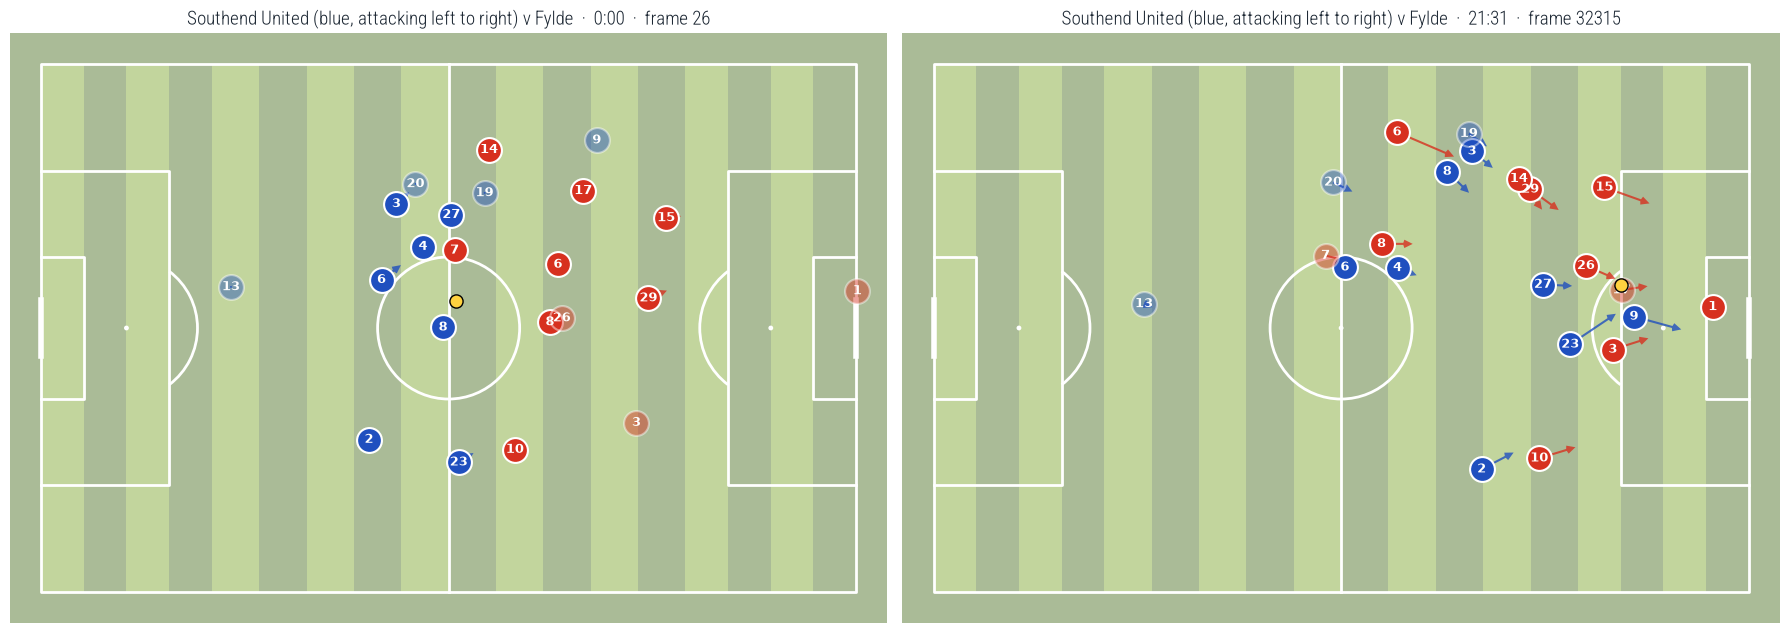

In [10]:
players_per_frame = m.players.groupby("frame").size()
kick_off = int(players_per_frame[players_per_frame == 22].index[0])  # first frame with everyone in shot
in_box = m.ball[(m.ball.clock > 20 * 60) & (m.ball.x > 36) & (m.ball.y.abs() < 20)]
attack = int(in_box.frame.iloc[0])
print(f"kick-off frame {kick_off}; ball in Fylde's box at {clock_label(in_box.clock.iloc[0], 1)} (frame {attack})")
fig = plot_frames(m, [kick_off, attack])

## Physical report

From the API's physical summary (`/matches/{id}/physicaldata`), which does not need the
tracking file. The speed bands, checked against the tracking it is built from:

| band | speed |
|---|---|
| running | 15-20 km/h |
| high-speed running (HSR) | 20-25 km/h |
| sprinting | over 25 km/h |
| high intensity (HI) | over 20 km/h - HSR plus sprinting |

Southend are always the subject - their players are the marks, in blue - and the opposition
are grey reference lines and dots. Goalkeepers are left out: their running is a different job,
and the API does not always include them (Sims is missing here).

In [11]:
pm = physical_match(MATCH_ID)
for goal in pm.goals:
    print(f"{goal.minute:5.1f}'  {pm.team_name(goal.team):16} {goal.scorer}{' (og)' if goal.own_goal else ''}")

  1.6'  Southend United  D. Oldaker


 11.6'  Fylde            B. Goodliffe (og)
 15.1'  Southend United  R. Colclough
 50.1'  Southend United  B. Goodliffe


### The match in four numbers

Team totals for the outfield players, Southend against Fylde.

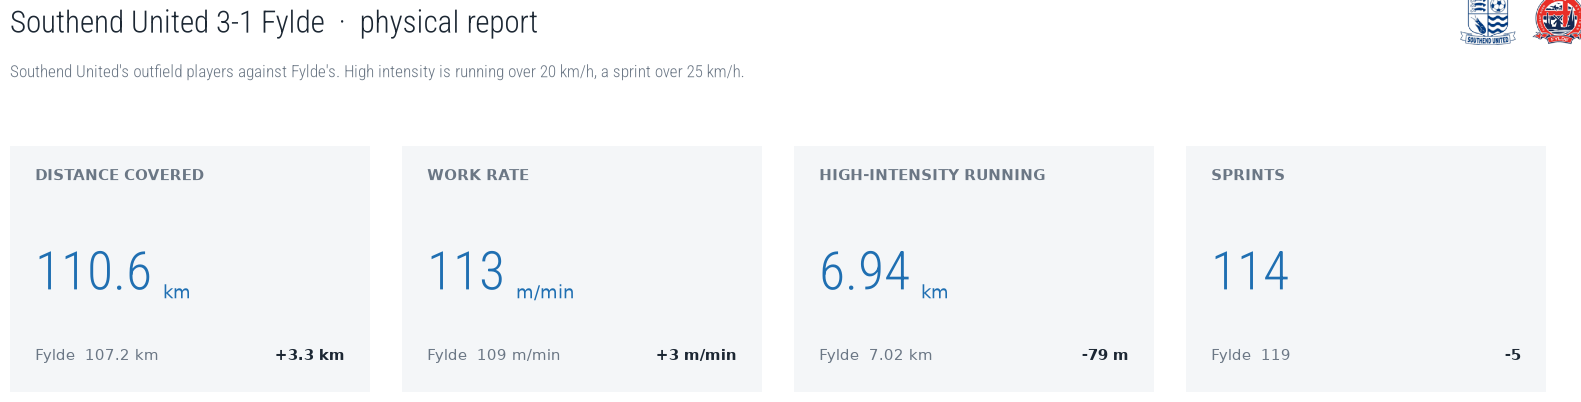

In [12]:
fig = plot_physical_headline(pm, TEAM)

### Who ran furthest

Distance, work rate (metres per minute on the pitch - the fair way to compare a substitute with
a starter) and high-intensity metres split into high-speed running and sprinting. The grey line
in each panel is Fylde's best player (their average, for work rate).

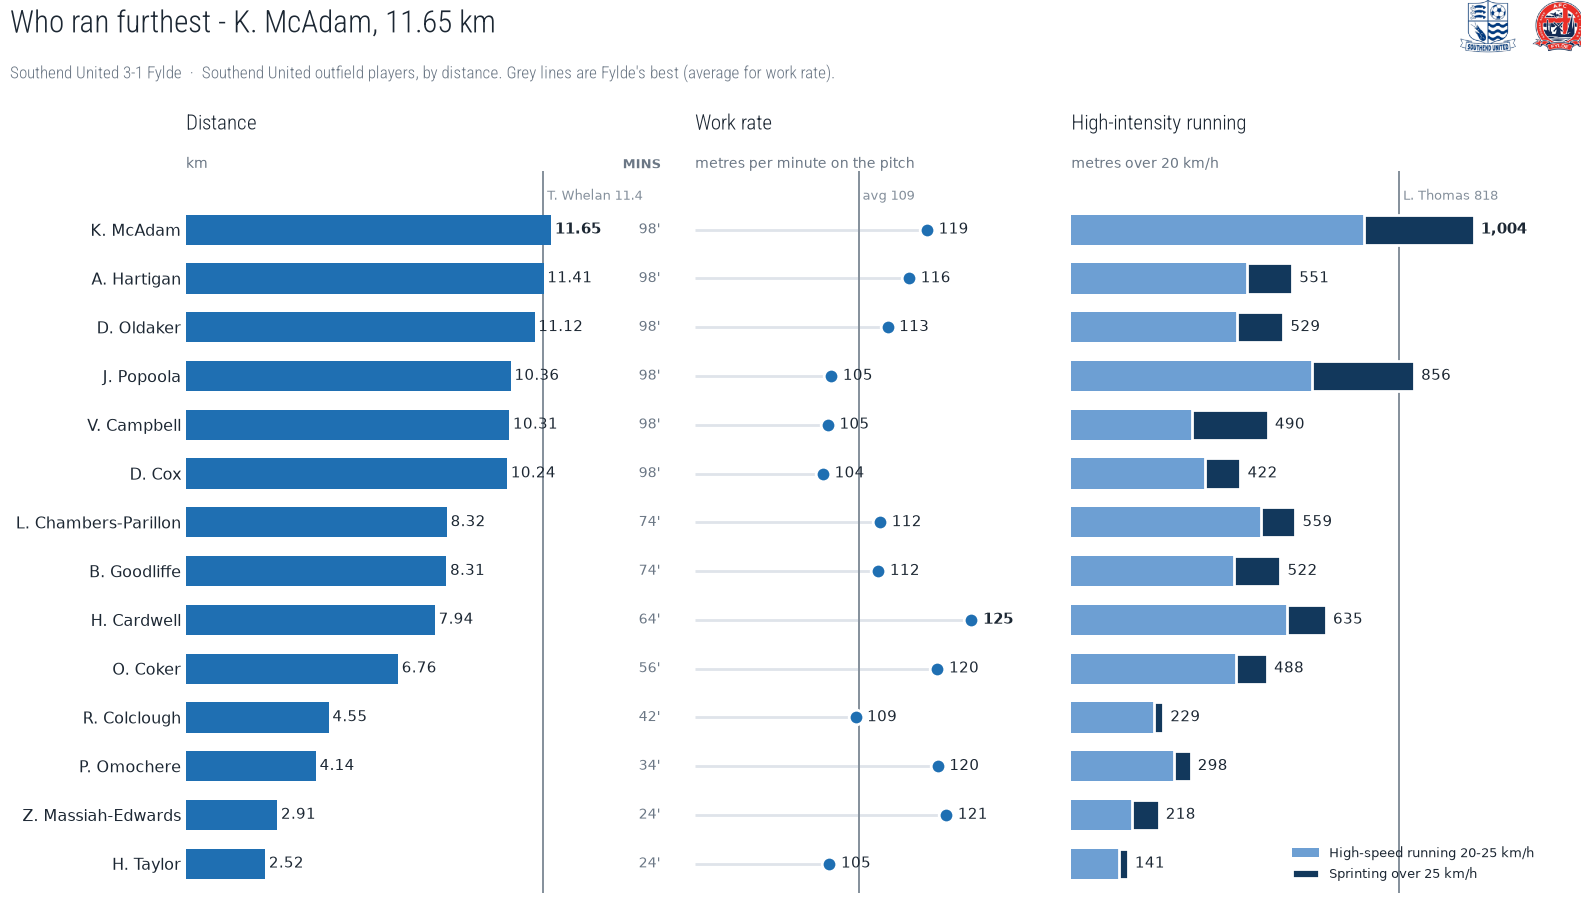

In [13]:
fig = plot_distance_ladder(pm, TEAM)

### High-speed runs and sprints

How often each outfield player ran at 20-25 km/h, and how often they went flat out over
25 km/h. The grey cross is the median of everyone on the pitch. Substitutes and players taken
off show their minutes, since these are counts.

There is no top speed in this report. The API's is the single fastest frame, and the
tracking's speed spikes: it made Cox Southend's fastest at 34.9 km/h, when the most he held for
a whole second was 27.2. Checked against how far players actually moved, the tracking cannot
reliably say who was fastest, so it is left out rather than shown wrong.

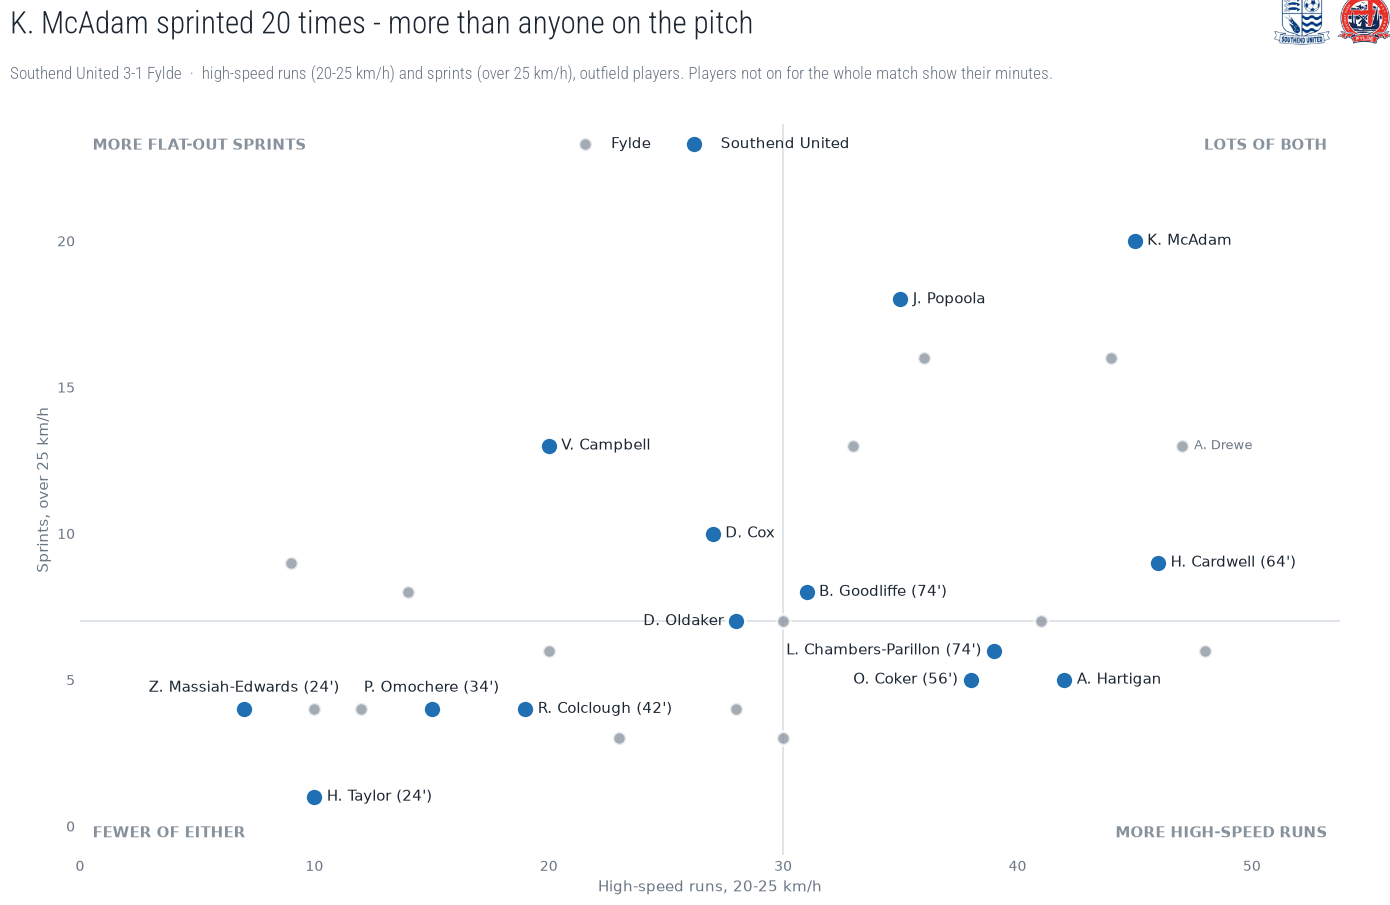

In [14]:
fig = plot_runs_and_sprints(pm, TEAM)

### Intensity through the match

High-intensity running per minute in each 15-minute spell (the API's blocks; the third and sixth
include added time). The top chart adds up every outfield player for each team, with the goals
marked; the grid below breaks Southend down player by player, to show who faded and who came
on and lifted it.

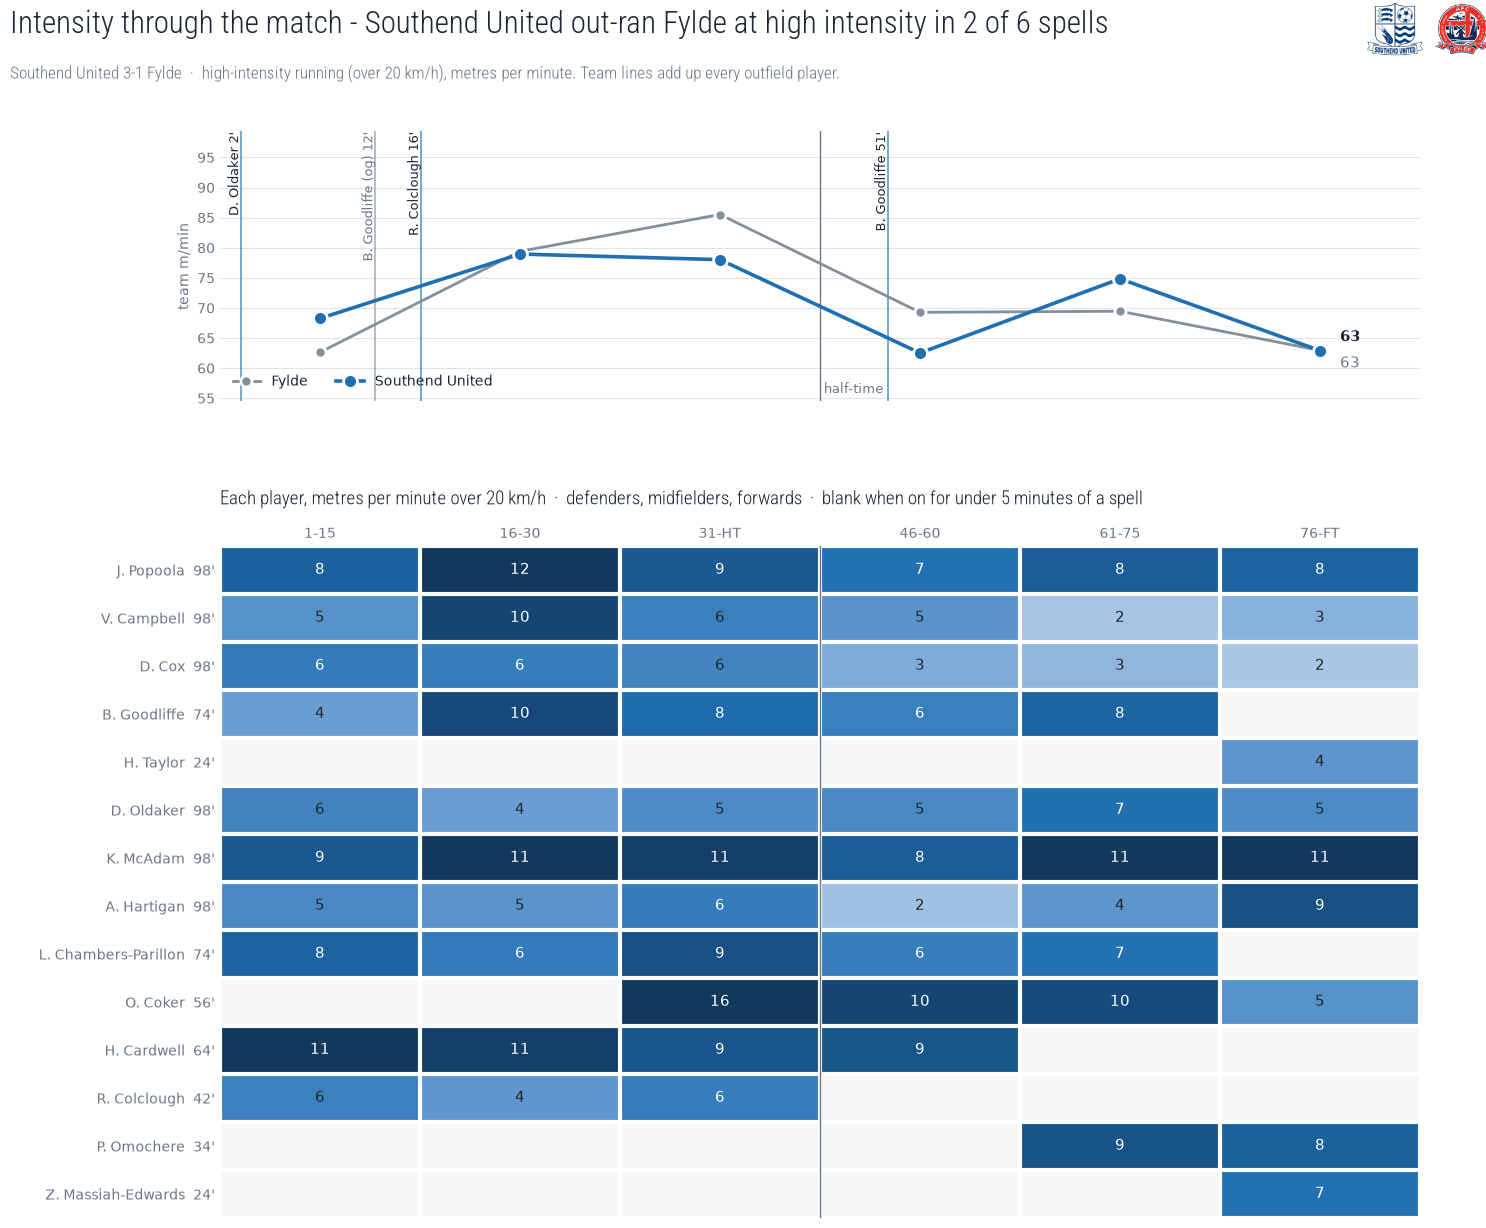

In [15]:
fig = plot_intensity_timeline(pm, TEAM)

### Bursts

High accelerations and decelerations - speeding up or slowing down faster than 3 m/s² for at
least half a second, the sharp changes of pace that pressing, recovering and changing direction
take out of a player.

These are counted from the tracking rather than taken from the API. When the camera loses a
player the provider fills the gap with a straight line and reports their speed as 0, so the
speed drops to 0 and jumps back - and the API counts each of those as a burst. Harry Taylor,
whom the tracking kept losing, had 43 high accelerations in 24 minutes from the API (161 per
90, double anyone else); with a second either side of every filled gap skipped it is 23. The
table shows both counts and how many seconds around filled gaps were skipped for each player.

In [16]:
bursts = burst_counts(m)
compare = bursts.merge(pm.players[["player_id", "high_accels", "high_decels"]], on="player_id",
                       suffixes=("", "_api"))
compare[compare.team == "home"].sort_values("skipped_seconds", ascending=False).round(1)

,team,jersey,name,player_id,minutes,skipped_seconds,high_accels,high_decels,high_accels_api,high_decels_api
8,home,3,Kyle McAdam,622808,98.2,174.9,84,94,105.0,118.0
2,home,6,Ben Goodliffe,445813,74.2,123.0,57,53,68.0,77.0
4,home,4,Anthony Hartigan,518018,98.2,104.7,74,60,81.0,63.0
3,home,19,Leon Chambers-Parillon,702447,74.2,90.1,63,50,71.0,73.0
1,home,9,Harry Cardwell,330285,63.7,82.6,71,50,77.0,76.0
0,home,27,Ryan Colclough,231737,41.8,80.4,31,31,39.0,35.0
9,home,2,Vontae Daley-Campbell,447198,98.2,79.2,57,45,64.0,64.0
10,home,16,Harry Taylor,353931,24.0,75.8,23,14,43.0,28.0
6,home,8,Darren Oldaker,386725,98.2,73.3,39,51,50.0,76.0
7,home,23,Josh Popoola,896621,98.2,68.1,75,73,93.0,93.0


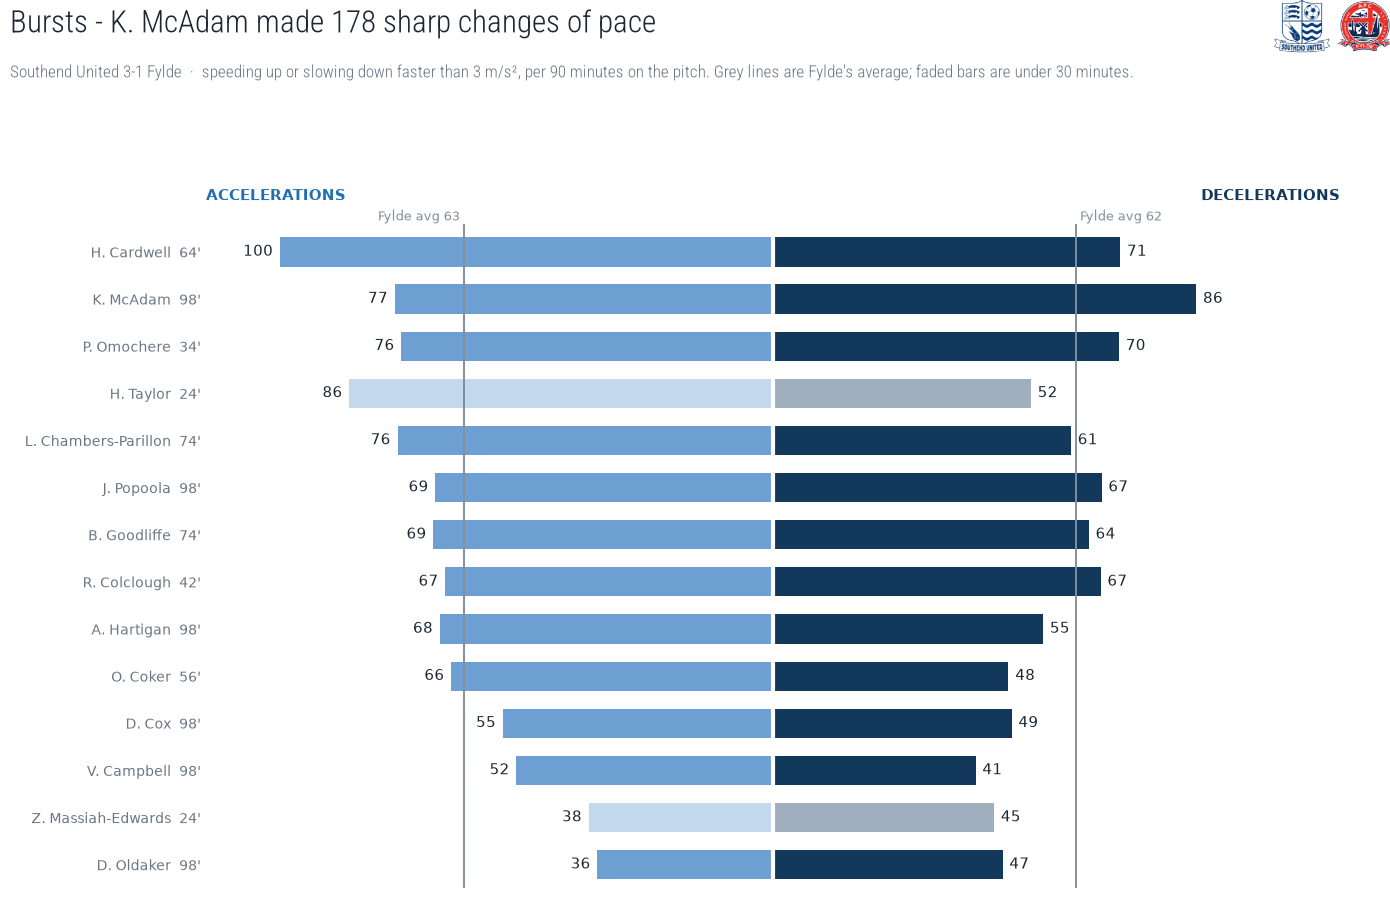

In [17]:
fig = plot_accelerations(pm, TEAM, bursts=bursts)

## Tracking visuals

What the frame-by-frame positions add, from Southend's side: Southend always attack left to
right, Fylde are grey. `wyscout.data.tracking_stats` does the sums.

What the tracking can and cannot be trusted for decided what is here:

- **Filled gaps are dropped everywhere.** When the camera loses a player the provider draws a
  straight line, sometimes at 50 km/h - those frames are left out of every chart.
- **No possession, no goal replays.** The tracking does not say who had the ball, and two thirds
  of the ball positions are estimates - at the goal times the ball never reaches the goal
  line. So nothing here splits by in and out of possession, and the ball is only used where
  the camera saw it.
- **Averages over minutes, not single frames.** Positions glitch now and then, so the charts
  use medians over many frames, or (for sprints) runs whose speed and distance agree.

In [18]:
SIDE = "home" if pm.home == TEAM else "away"
runs = ts.sprints(m, SIDE)
print(f"{len(runs)} sprints, {runs.suspect.sum()} left out where the position glitched mid-run")
runs[~runs.suspect].groupby("name").agg(sprints=("forward", "size"), forward=("forward", "sum"),
                                        avg_metres=("metres", "mean")).sort_values("sprints", ascending=False).round(1)

113 sprints, 7 left out where the position glitched mid-run


,sprints,forward,avg_metres
name,,,
Kyle McAdam,19,13,23.100000
Josh Popoola,17,11,21.100000
Vontae Daley-Campbell,13,5,21.700001
Darren Oldaker,9,7,24.799999
Harry Cardwell,9,8,17.700001
Daniel Cox,8,3,15.300000
Leon Chambers-Parillon,7,5,23.900000
Ben Goodliffe,6,1,20.200001
Oliver Coker,5,3,21.100000


### Territory and sprints

One pitch per player: where they spent their time (grey, darker where they were most), and an
arrow for every run that hit sprint speed - over 25 km/h for at least 0.6 s, which matches the
API's sprint counts - drawn from when they passed 20 km/h to when they dropped back under it.
Dark arrows went forward, light ones back towards Southend's goal.

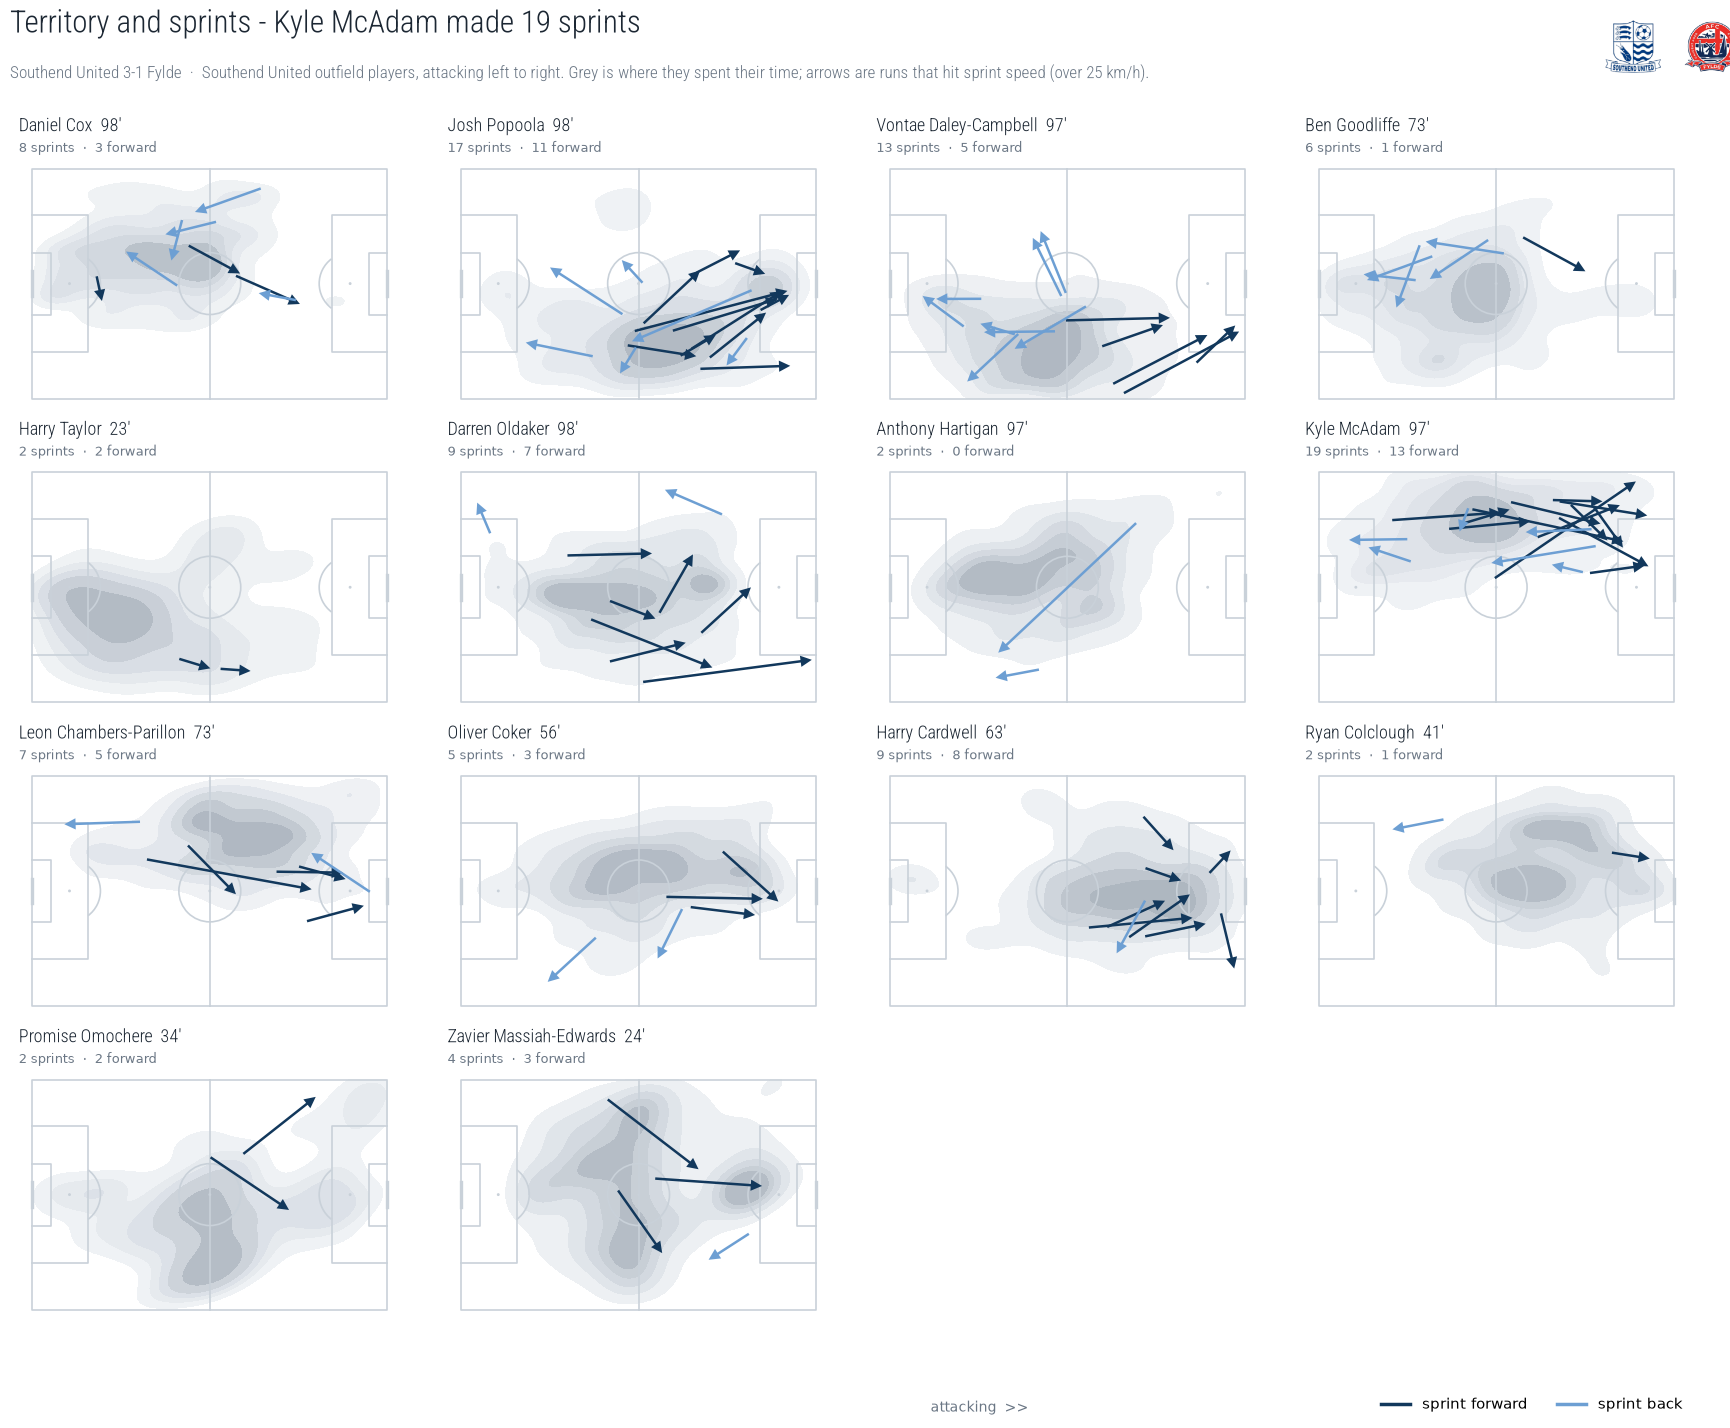

In [19]:
fig = plot_player_territories(m, pm, TEAM, runs)

### Shape by where the ball was

Southend's average positions when the camera saw the ball in each third - how the block moves
as the ball does. The shaded outline joins the outfield players; grey dots are Fylde's average
positions over the same moments.

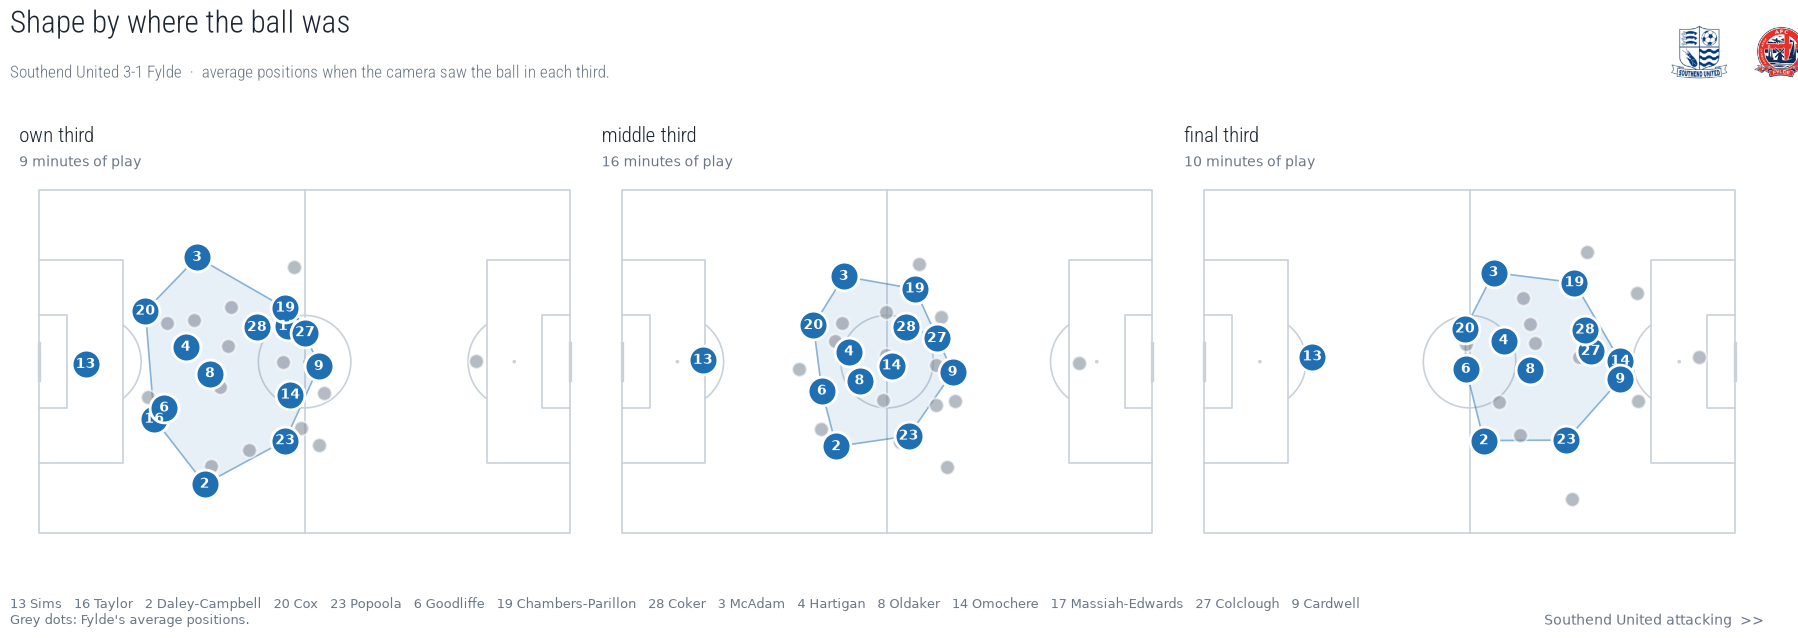

In [20]:
fig = plot_average_shapes(
    m, pm, TEAM, ts.ball_zone_frames(m, SIDE),
    "Shape by where the ball was",
    "average positions when the camera saw the ball in each third.",
)

### Shape by scoreline

The same, at each score (scorelines lasting under five minutes are left out). Substitutes
appear in the score they played most of.

,score,minutes,line_height,length,width
0,1-0,10.0,44.8,31.1,41.2
1,2-1,38.1,45.8,31.8,38.4
2,3-1,45.0,33.4,32.1,38.7


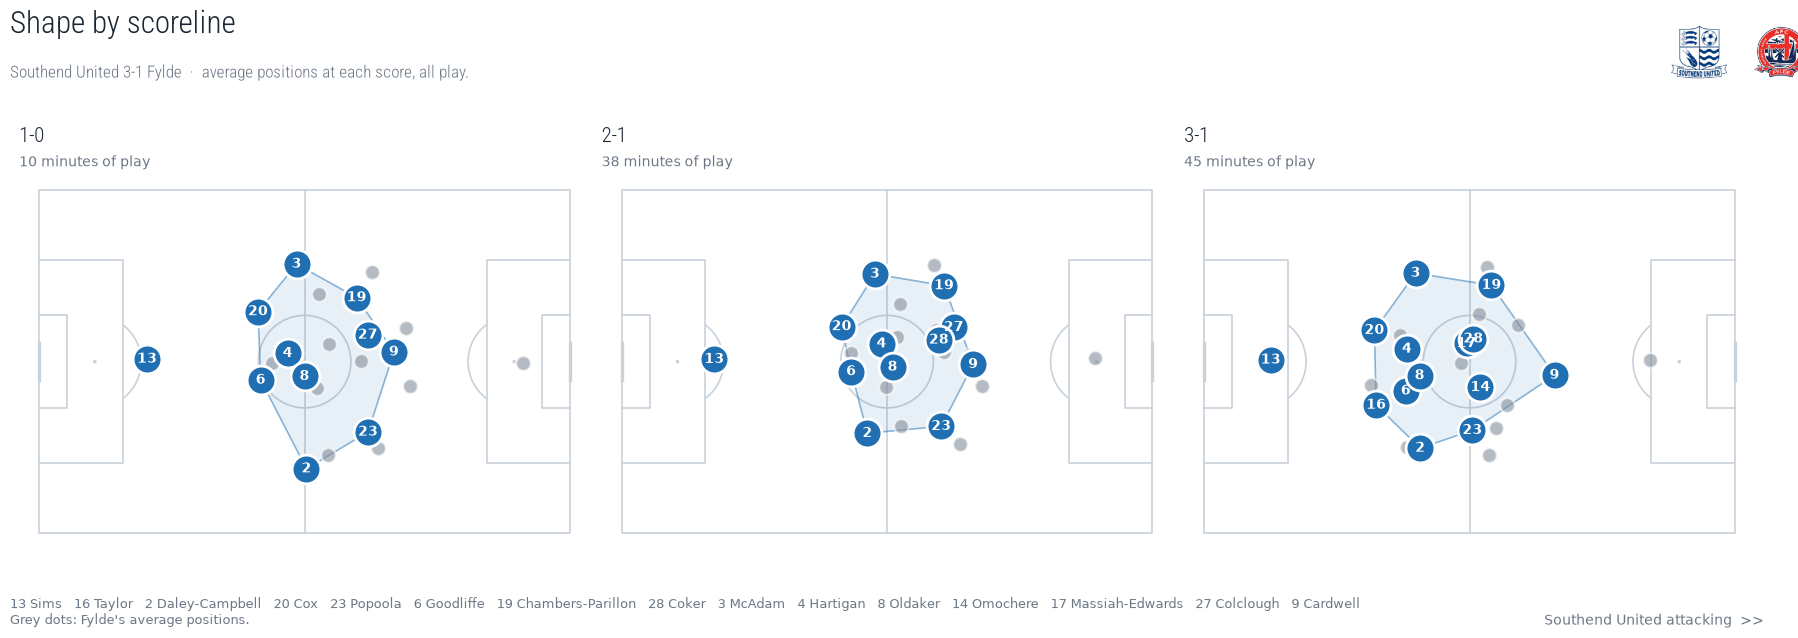

In [21]:
fig = plot_average_shapes(
    m, pm, TEAM, ts.score_frames(m, SIDE, pm.goals),
    "Shape by scoreline",
    "average positions at each score, all play.",
)
ts.shape_by_score(m, SIDE, pm.goals).round(1)

### Shape through the match

Minute by minute with the ball in play: how far Southend's deepest four sat from their own goal,
and how long and wide the outfield ten were. Fylde in grey. Each minute is a median and the lines
are smoothed over five, so a single attack does not move them; even so, the back line mostly
follows where the ball was, so read it as territory as much as instruction.

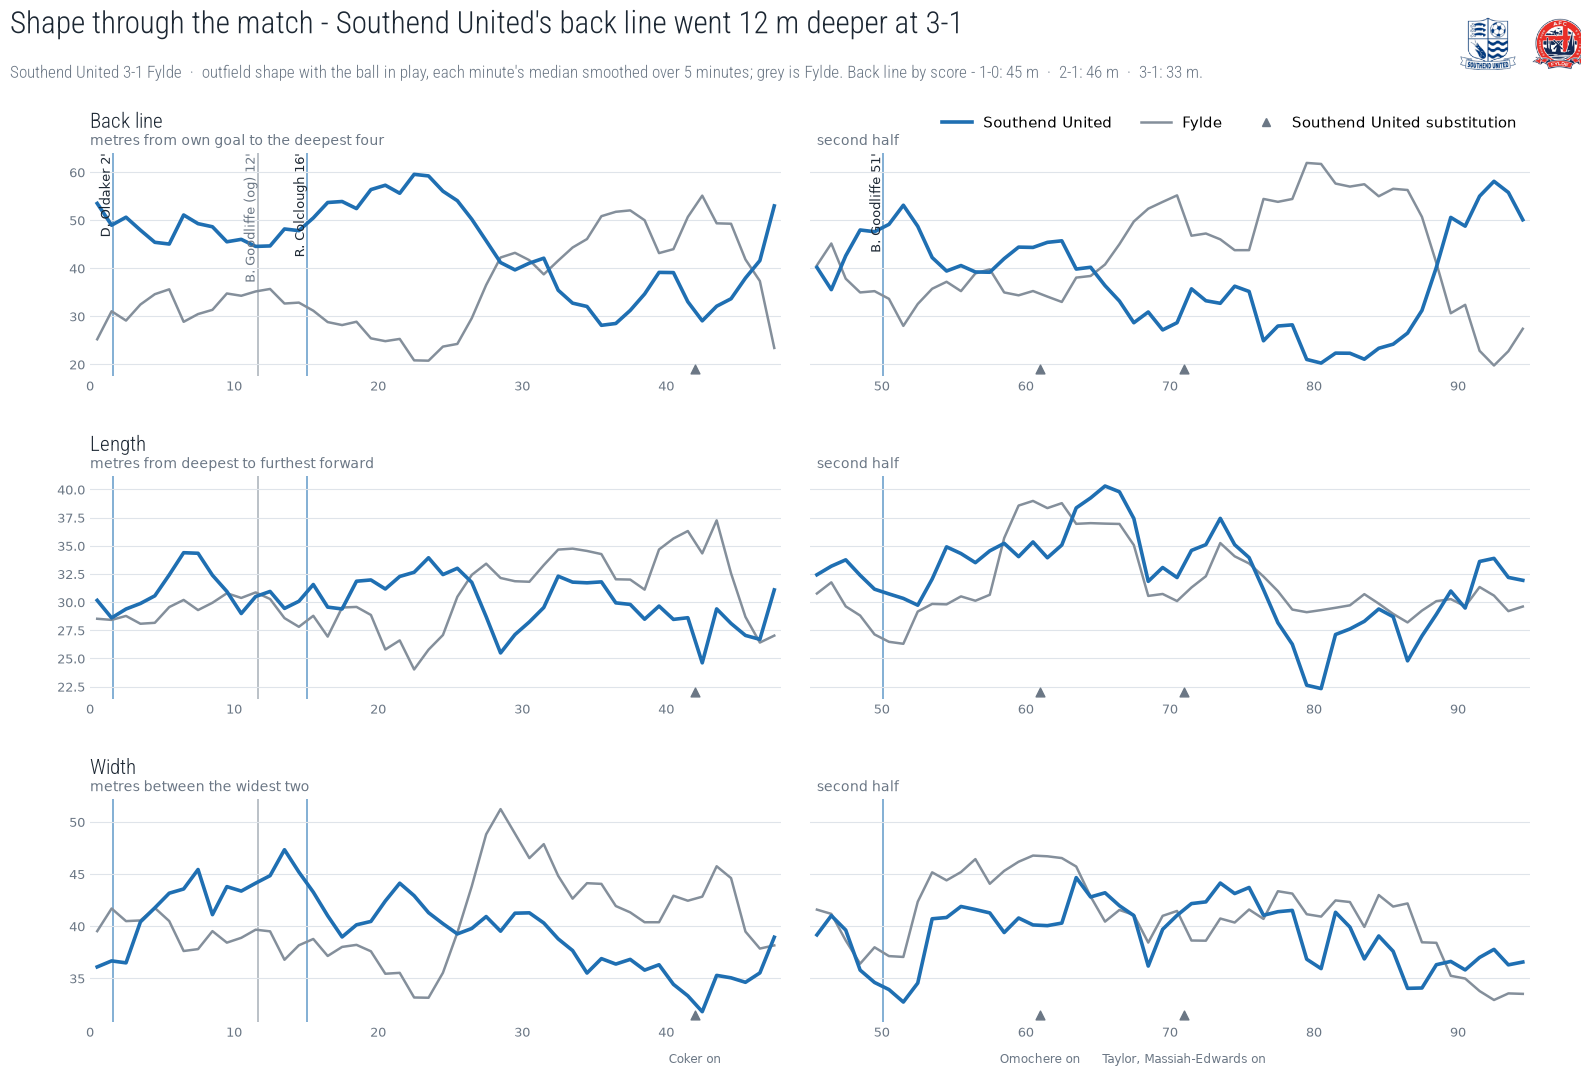

In [22]:
fig = plot_shape_timeline(m, pm, TEAM)

### The goals

Every player at the moment each goal was struck. Wyscout's events carry a timestamp into the
match video, and the tracking is built from the same Wyscout video at one frame every 40 ms, so
the shot can be put on the exact frame.

The tracked ball is not used: around a shot it is mostly the model's estimate and jumps about
(at Oldaker's shot it moves 10 m backwards). The ball is drawn at the scorer's feet instead,
with a line to the goal it went in. The table checks the sync - how far the tracked scorer was
from where Wyscout logged the shot. Wyscout's locations are hand-coded, so a few metres is
normal.

In [23]:
from pathlib import Path

moments = ts.goal_moments(m, MATCH_ID)
check = []
for g in moments:
    scorer = m.players[(m.players.frame == g.frame) & (m.players.team == g.scorer_side)
                       & (m.players.jersey == g.scorer_jersey)]
    check.append({
        "minute": int(g.minute) + 1, "scorer": g.scorer, "own goal": g.own_goal, "frame": g.frame,
        "metres from Wyscout's location": float(np.hypot(scorer.x - g.ball_x, scorer.y - g.ball_y).iloc[0]),
        "scorer seen by camera": bool(scorer.visible.iloc[0]),
    })
pd.DataFrame(check).round(1)

,minute,scorer,own goal,frame,metres from Wyscout's location,scorer seen by camera
0,2,D. Oldaker,False,2412,1.2,True
1,12,B. Goodliffe,True,17494,6.2,True
2,16,R. Colclough,False,22629,7.6,True
3,51,B. Goodliffe,False,79811,3.8,False


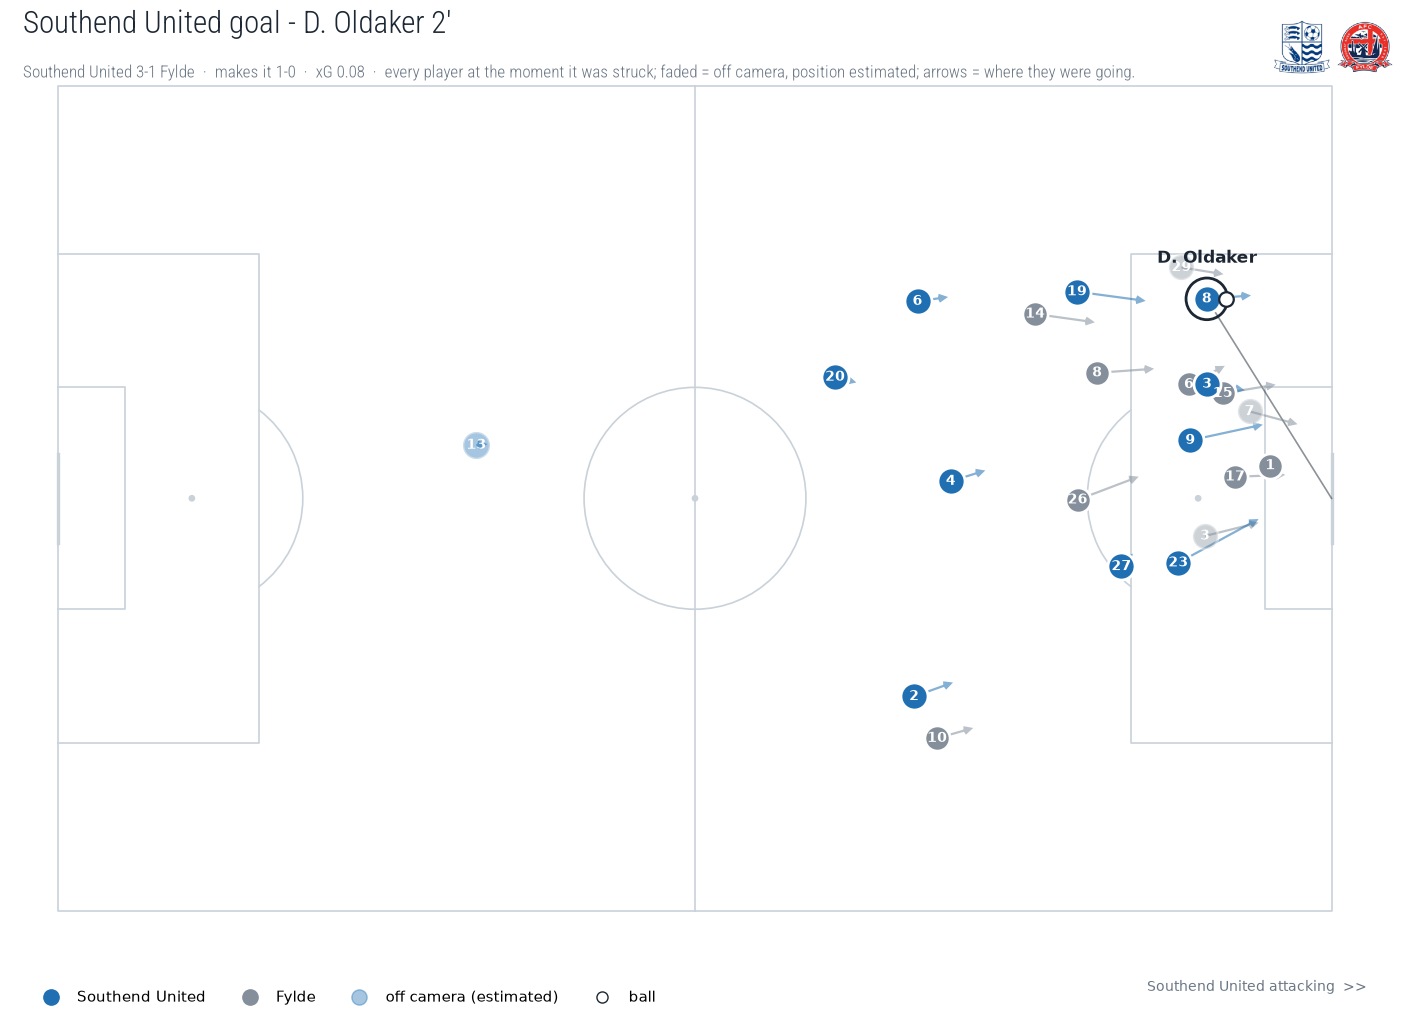

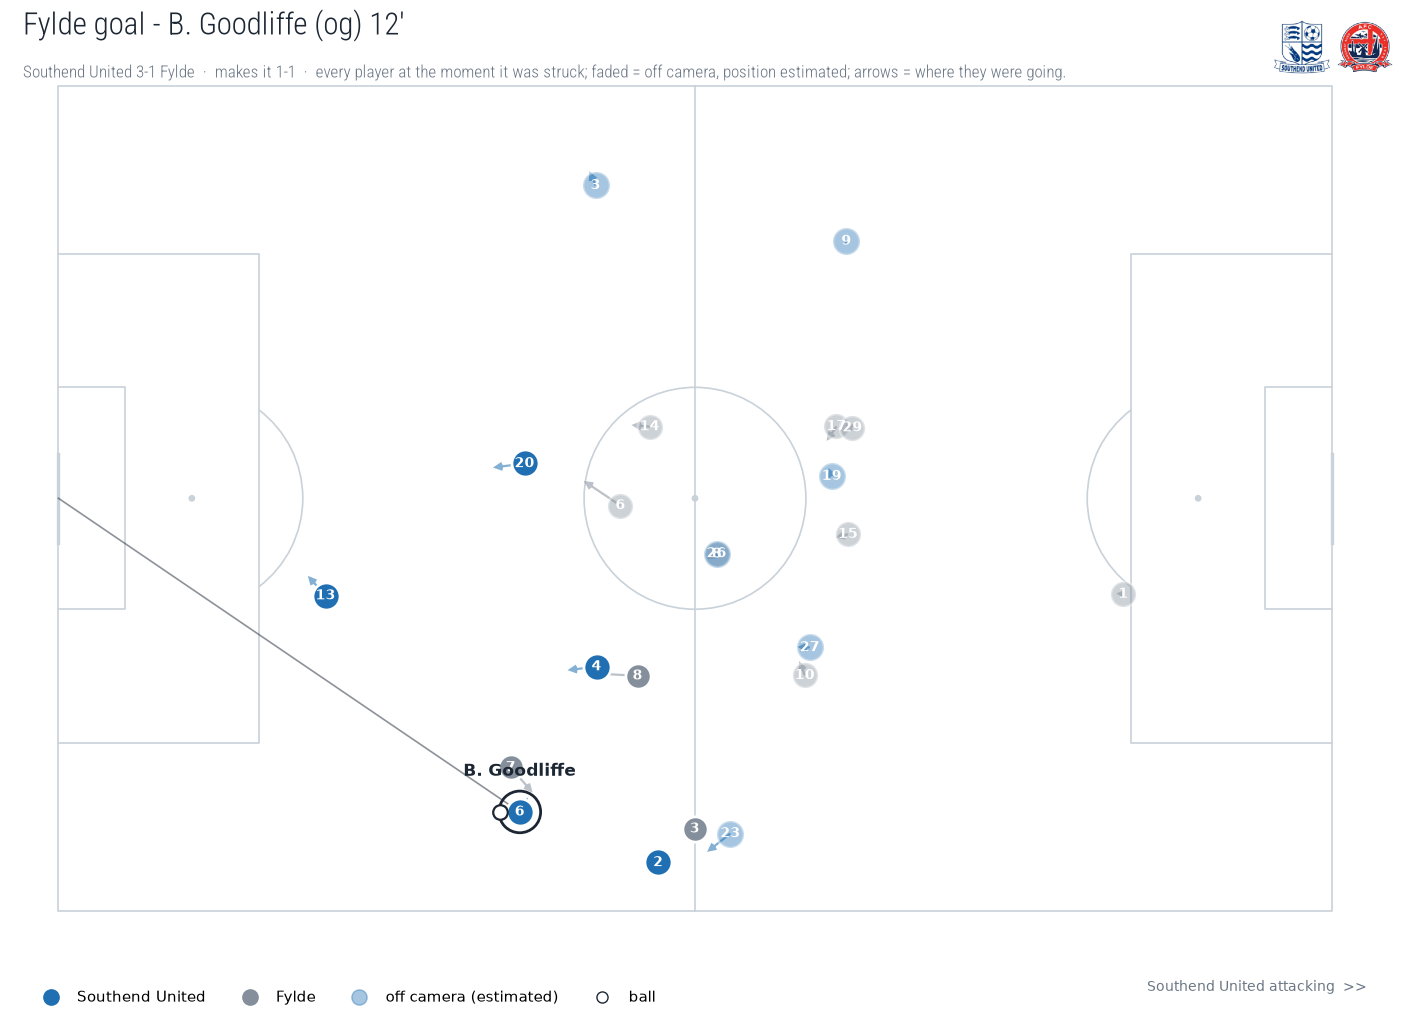

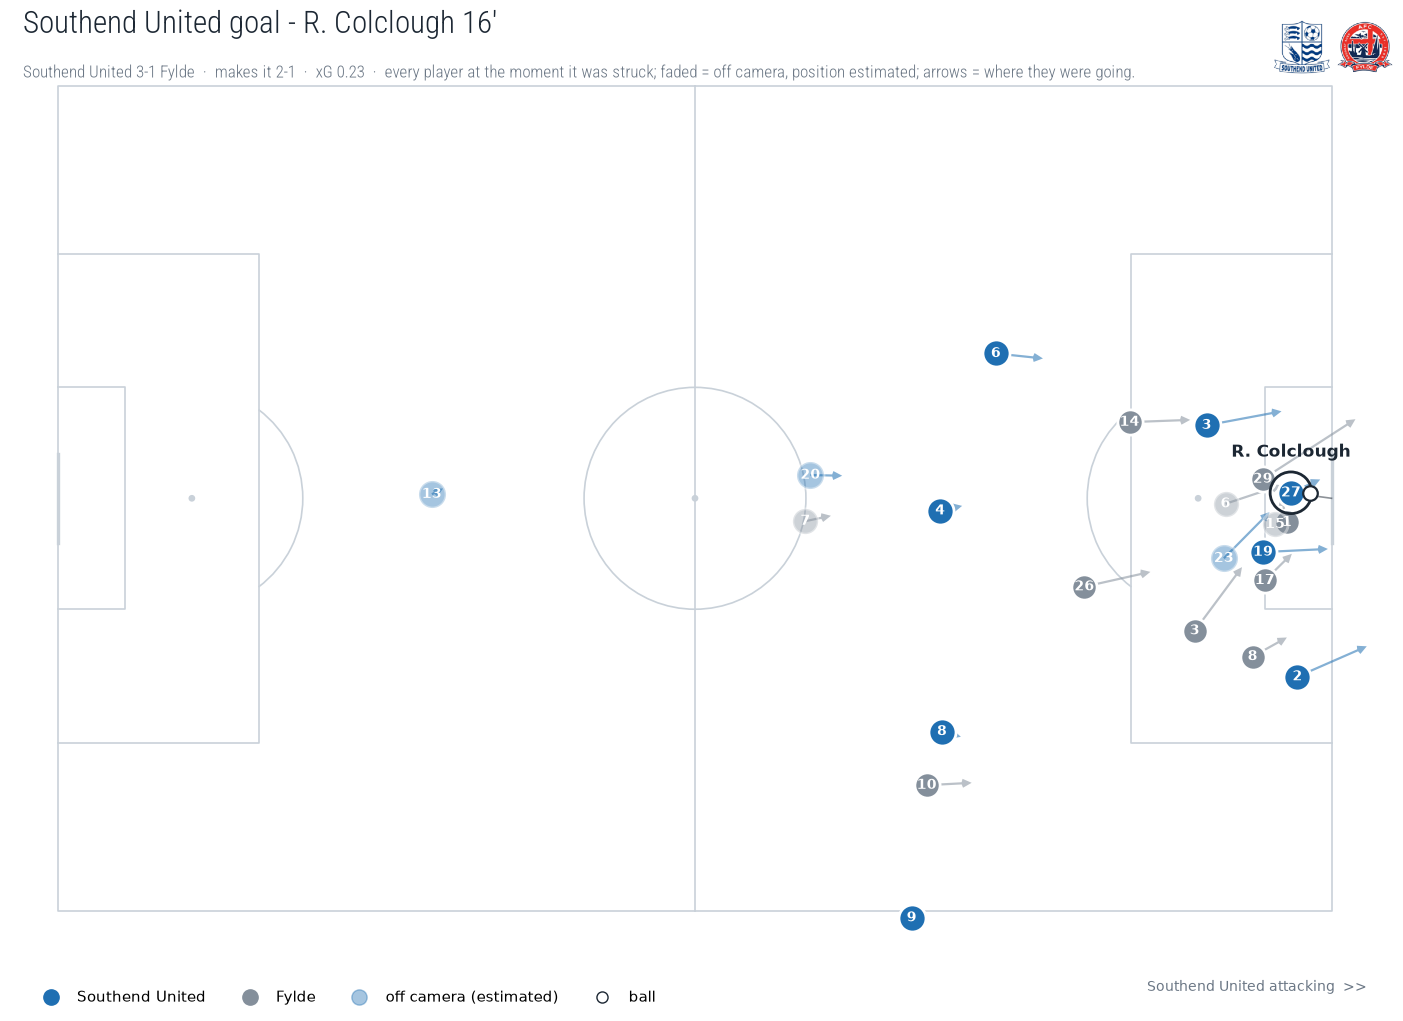

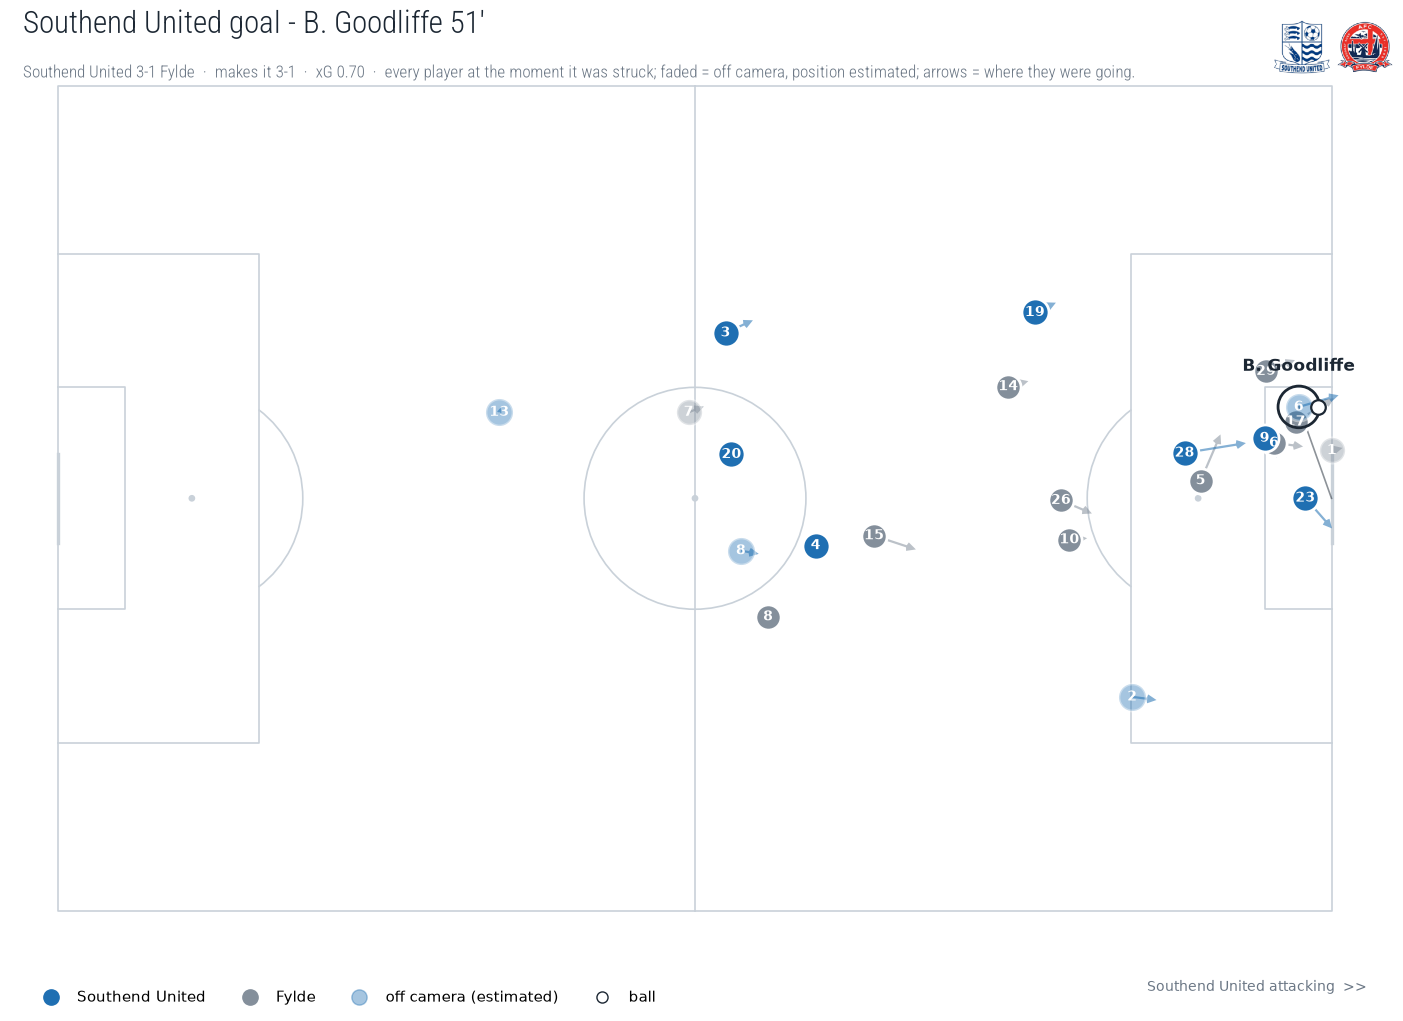

In [24]:
Path("imgs").mkdir(exist_ok=True)
for i, moment in enumerate(moments, 1):
    fig = plot_goal_moment(m, pm, TEAM, moment, save_path=f"imgs/goal_{i}.png")